# Solving the Traveling Salesman  Problem using Local Search

Points: 10

## The [Traveling Salesman Problem](https://en.wikipedia.org/wiki/Travelling_salesman_problem)

* __Goal:__ Find the shortest tour visiting each of $n$ cities exactly once and returning back to the starting city. Given are pairwise distances between cities, where $d_{i,j}$ is the distance from city $i$ to city $j$. 

* __State space:__ Each state represents a tour. The cities are numbered and a tour can be expressed as vector  $\pi$ with the order in which the cities are visited (a [permutation](https://en.wikipedia.org/wiki/Permutation)). That is, $\pi(1)$ is the index of the first city to visit, $\pi(2)$ the index of the second, and so on.

* __Objective function:__ Minimize the tour length. The optimization problem is to find the optimal tour $\pi^*$ through the $n$ cities and returning to the starting city:

  > minimize: $\mathrm{tourlength}(\pi) = d_{\pi(n),\pi(1)} + \sum_{i = 1}^{n-1} d_{\pi(i),\pi(i+1)}$
  > 
  > subject to: $\pi \ \text{is a valid permutation vector}$

* __Local moves:__ Exchange two cities in the order.

## Helper functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)

# make the results repeatable
np.random.seed(1234)

In [2]:
def random_tour(n):
    """Create a random tour"""
    
    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[4, 8, 2, 6, 1, 3, 5, 7, 9, 0]

In [18]:
try:
    from scipy.spatial.distance import pdist, squareform
except ModuleNotFoundError:
    def pdist(X):
        X = np.asarray(X, dtype=float)
        diff = X[:, None, :] - X[None, :, :]
        dist = np.linalg.norm(diff, axis=2)
        i, j = np.triu_indices(len(X), k=1)
        return dist[i, j]

    def squareform(d):
        d = np.asarray(d, dtype=float)
        n = int((1 + np.sqrt(1 + 8 * len(d))) / 2)
        dist = np.zeros((n, n), dtype=float)
        i, j = np.triu_indices(n, k=1)
        dist[i, j] = d
        dist[j, i] = d
        return dist
# scipy is already imported above, or the fallback implementations are defined.
# Do not import scipy.spatial.distance again here.

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calulates a 
    pairwise Euclidean distance matrix.
    """
    
    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })
    
    dist = squareform(pdist(pos))
    
    return({"pos": pos, "dist": dist})
    
tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])})")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00)


In [19]:
def tour_length(tsp, tour):
    """Caclulate the length of a tour, i.e., the objective function."""
    
    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()
    
    tl = 0
    dist = tsp["dist"]
    
    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]
    
    tl += dist[tour[-1], tour[0]]
    
    return(tl)
        
tour = random_tour(10)
tour_length(tsp, tour)

np.float64(4.943798767765629)

Tour length: 4.94


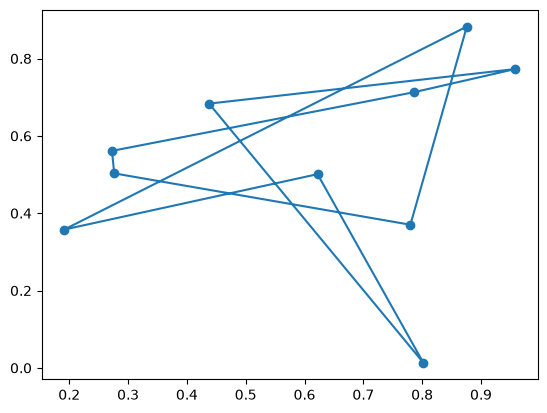

In [20]:
def show_tsp(tsp, tour = None):  
    """display the traveling salesman problem and a tour."""
    
    pos = tsp["pos"]
    
    plt.scatter(pos["x"], pos["y"])
    
    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()
        
        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")
        
        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])
    
    plt.show()
    
show_tsp(tsp, tour)

## Steepest-ascend Hill Climbing Search [3 Points]

Calculate the objective function for all local moves (move each queen within its column) and always choose the best among all local moves.

Tour ban đầu:
Tour length: 4.94


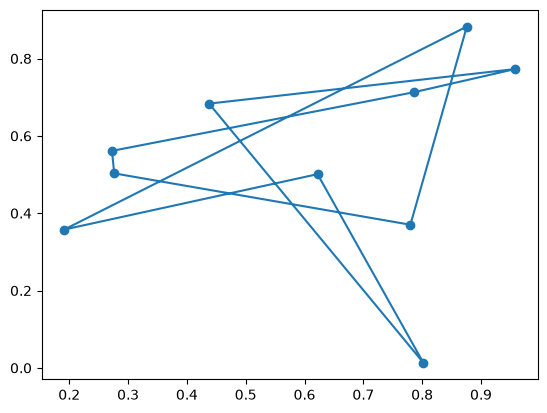

Sau Steepest-Ascent HC (5 bước, 271 lần tính hàm mục tiêu):
Tour length: 2.88


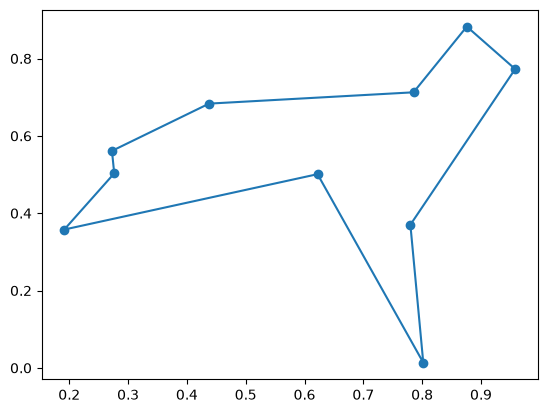

In [21]:
# Mô tả toán tử lân cận cho TSP:
# Ta cài đặt và hỗ trợ cả 2 toán tử phổ biến:
# 1. Toán tử 2-swap (Exchange two cities): Chọn 2 vị trí i < j và hoán đổi tour[i], tour[j]. Số láng giềng = n*(n-1)/2.
# 2. Toán tử 2-opt (Reverse segment): Đảo ngược đoạn tour[i:j+1] để gỡ các cạnh cắt chéo. Số láng giềng = n*(n-1)/2.
# Để đảm bảo công bằng khi so sánh các thuật toán, ta giữ cố định toán tử 'swap' (theo đúng mô tả đề bài "Exchange two cities in the order"),
# đồng thời cung cấp tùy chọn '2opt' để đối chiếu.

def get_neighbor_tour(tour, i, j, operator="swap"):
    new_tour = tour.copy()
    if operator == "swap":
        new_tour[i], new_tour[j] = new_tour[j], new_tour[i]
    elif operator == "2opt":
        new_tour[i:j+1] = reversed(new_tour[i:j+1])
    return new_tour

def tsp_steepest_ascend_hc(tsp, init_tour=None, operator="swap", return_stats=False):
    n = len(tsp["pos"])
    current = list(init_tour) if init_tour is not None else random_tour(n)
    current_len = tour_length(tsp, current)
    steps = 0
    evals = 1

    while True:
        best_len = current_len
        best_tour = None

        for i in range(n - 1):
            for j in range(i + 1, n):
                cand = get_neighbor_tour(current, i, j, operator)
                cand_len = tour_length(tsp, cand)
                evals += 1
                if cand_len < best_len - 1e-12:
                    best_len = cand_len
                    best_tour = cand

        if best_tour is not None:
            current = best_tour
            current_len = best_len
            steps += 1
        else:
            break

    if return_stats:
        return current, current_len, steps, evals
    return current

# Kiểm thử và hiển thị tour trước/sau khi tối ưu bằng Steepest-Ascent HC
random.seed(1234)
np.random.seed(1234)
init_t10 = random_tour(10)
print("Tour ban đầu:")
show_tsp(tsp, init_t10)

sol_steep, len_steep, st_steep, ev_steep = tsp_steepest_ascend_hc(tsp, init_t10, operator="swap", return_stats=True)
print(f"Sau Steepest-Ascent HC ({st_steep} bước, {ev_steep} lần tính hàm mục tiêu):")
show_tsp(tsp, sol_steep)

## Steepest-ascend Hill Climbing Search with Random Restarts [1 Point]

Steepest-ascend with random restarts.

Steepest-Ascent với 20 Random Restarts -> Chiều dài tour tốt nhất: 2.7636 (Tổng bước: 100)
Tour length: 2.76


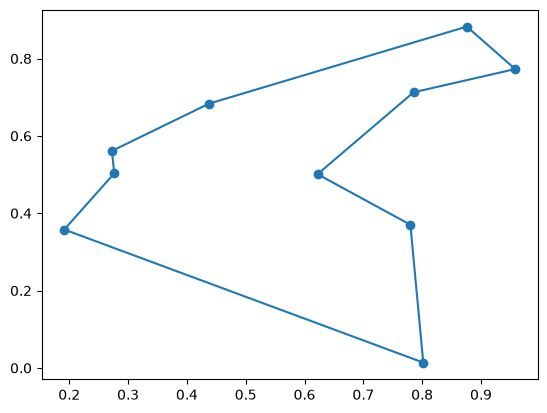

In [22]:
def tsp_random_restart_hc(tsp, restarts=20, operator="swap", return_stats=False):
    n = len(tsp["pos"])
    best_tour = None
    best_len = float("inf")
    total_steps = 0
    total_evals = 0

    for _ in range(restarts):
        t_init = random_tour(n)
        sol, length, steps, evals = tsp_steepest_ascend_hc(tsp, t_init, operator=operator, return_stats=True)
        total_steps += steps
        total_evals += evals
        if length < best_len:
            best_len = length
            best_tour = sol

    if return_stats:
        return best_tour, best_len, total_steps, total_evals
    return best_tour

random.seed(1234)
sol_rr, len_rr, st_rr, ev_rr = tsp_random_restart_hc(tsp, restarts=20, operator="swap", return_stats=True)
print(f"Steepest-Ascent với 20 Random Restarts -> Chiều dài tour tốt nhất: {len_rr:.4f} (Tổng bước: {st_rr})")
show_tsp(tsp, sol_rr)

## Stochastic Hill Climbing [1 Points]

Chooses randomly from among all uphill moves.

Stochastic HC -> Chiều dài tour: 2.9062 (Số bước: 14, Số lần đánh giá: 676)
Tour length: 2.91


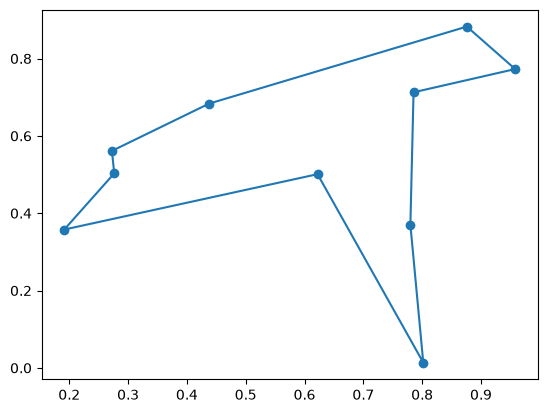

In [23]:
def tsp_stochastic_hc(tsp, init_tour=None, operator="swap", return_stats=False):
    """Liệt kê tất cả các láng giềng ngắn hơn tour hiện tại và chọn ngẫu nhiên 1 láng giềng."""
    n = len(tsp["pos"])
    current = list(init_tour) if init_tour is not None else random_tour(n)
    current_len = tour_length(tsp, current)
    steps = 0
    evals = 1

    while True:
        improving_moves = []
        for i in range(n - 1):
            for j in range(i + 1, n):
                cand = get_neighbor_tour(current, i, j, operator)
                cand_len = tour_length(tsp, cand)
                evals += 1
                if cand_len < current_len - 1e-12:
                    improving_moves.append((cand, cand_len))

        if len(improving_moves) > 0:
            current, current_len = random.choice(improving_moves)
            steps += 1
        else:
            break

    if return_stats:
        return current, current_len, steps, evals
    return current

random.seed(1234)
sol_shc, len_shc, st_shc, ev_shc = tsp_stochastic_hc(tsp, init_t10, operator="swap", return_stats=True)
print(f"Stochastic HC -> Chiều dài tour: {len_shc:.4f} (Số bước: {st_shc}, Số lần đánh giá: {ev_shc})")
show_tsp(tsp, sol_shc)

## First-choice Hill Climbing [1 Point]

First-choice hill climbing is a type of stochastic hill climbing that generates one random local neighbor at a time and accept it if it has a better objective function value than the current state.

First-Choice HC -> Chiều dài tour: 2.8927 (Số bước: 11, Số lần đánh giá: 222)
Tour length: 2.89


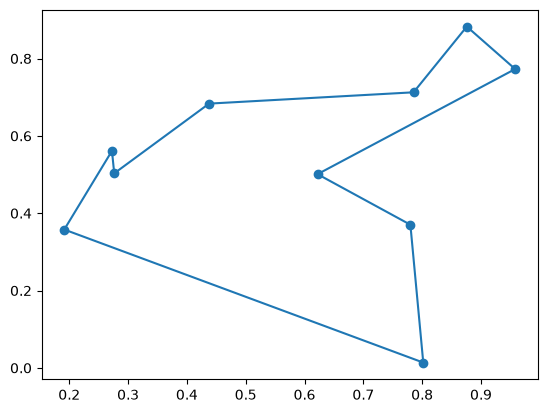

In [24]:
def tsp_first_choice_hc(tsp, init_tour=None, max_bad_tries=None, operator="swap", return_stats=False):
    """Sinh ngẫu nhiên từng láng giềng một, chấp nhận ngay nếu ngắn hơn tour hiện tại."""
    n = len(tsp["pos"])
    if max_bad_tries is None:
        max_bad_tries = 3 * (n * (n - 1) // 2)

    current = list(init_tour) if init_tour is not None else random_tour(n)
    current_len = tour_length(tsp, current)
    steps = 0
    evals = 1
    bad_tries = 0

    while bad_tries < max_bad_tries:
        i, j = sorted(random.sample(range(n), 2))
        cand = get_neighbor_tour(current, i, j, operator)
        cand_len = tour_length(tsp, cand)
        evals += 1

        if cand_len < current_len - 1e-12:
            current = cand
            current_len = cand_len
            bad_tries = 0
            steps += 1
        else:
            bad_tries += 1

    if return_stats:
        return current, current_len, steps, evals
    return current

random.seed(1234)
sol_fc, len_fc, st_fc, ev_fc = tsp_first_choice_hc(tsp, init_t10, operator="swap", return_stats=True)
print(f"First-Choice HC -> Chiều dài tour: {len_fc:.4f} (Số bước: {st_fc}, Số lần đánh giá: {ev_fc})")
show_tsp(tsp, sol_fc)

## Simulated Annealing [2 Points]

Simulated Annealing -> Chiều dài tour tốt nhất: 2.7636 (Số bước nhận: 247, Evals: 3675)
Tour length: 2.76


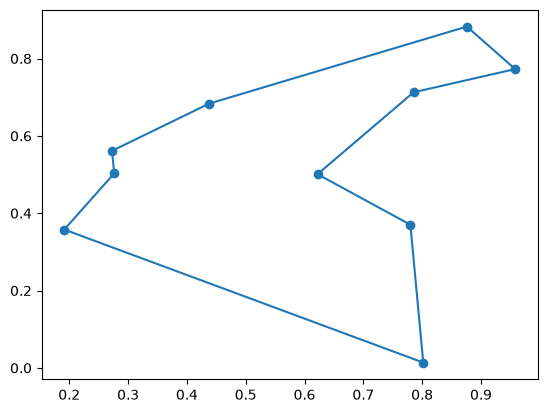

In [25]:
def tsp_simulated_annealing(tsp, init_tour=None, T0=1.0, alpha=0.995, max_iter=5000, operator="swap", return_stats=False):
    n = len(tsp["pos"])
    current = list(init_tour) if init_tour is not None else random_tour(n)
    current_len = tour_length(tsp, current)
    best_tour = current.copy()
    best_len = current_len
    steps = 0
    evals = 1

    for t in range(1, max_iter + 1):
        T = T0 * (alpha ** t)
        if T < 1e-8:
            break

        i, j = sorted(random.sample(range(n), 2))
        cand = get_neighbor_tour(current, i, j, operator)
        cand_len = tour_length(tsp, cand)
        evals += 1

        delta = cand_len - current_len
        if delta < 0 or random.random() < math.exp(-delta / T):
            current = cand
            current_len = cand_len
            steps += 1
            if current_len < best_len:
                best_len = current_len
                best_tour = current.copy()

    if return_stats:
        return best_tour, best_len, steps, evals
    return best_tour

random.seed(1234)
sol_sa_tsp, len_sa_tsp, st_sa_tsp, ev_sa_tsp = tsp_simulated_annealing(tsp, init_t10, operator="swap", return_stats=True)
print(f"Simulated Annealing -> Chiều dài tour tốt nhất: {len_sa_tsp:.4f} (Số bước nhận: {st_sa_tsp}, Evals: {ev_sa_tsp})")
show_tsp(tsp, sol_sa_tsp)

## Compare Performance [2 Points]

Use runtime, scalability (number of cities), and best objective function value to compare the algorithms on boards of different sizes.  

For timing you can use the `time` package.

In [13]:
import time

t0 = time.time()
print("Do something")
t1 = time.time()

print(f"This took: {(t1-t0) * 1e3} milliseconds")

Do something
This took: 0.11801719665527344 milliseconds


|   Cities (n) | Algorithm                     |   Init Tour Avg |   Best Length |   Avg Length | Improvement (%)   |   Avg Steps |   Avg Time (ms) |
|-------------:|:------------------------------|----------------:|--------------:|-------------:|:------------------|------------:|----------------:|
|           10 | Steepest-Ascent HC (swap)     |            6.58 |          3.39 |         3.44 | 47.8%             |         6.2 |            0.7  |
|           10 | Random Restart HC (10x, swap) |            6.58 |          3.39 |         3.39 | 48.4%             |        57.1 |            7.33 |
|           10 | Stochastic HC (swap)          |            6.58 |          3.39 |         3.48 | 47.1%             |        11.9 |            1.72 |
|           10 | First-Choice HC (swap)        |            6.58 |          3.39 |         3.39 | 48.4%             |        12.8 |            1.19 |
|           10 | Simulated Annealing (swap)    |            6.58 |          3.39 |         3.39 | 48

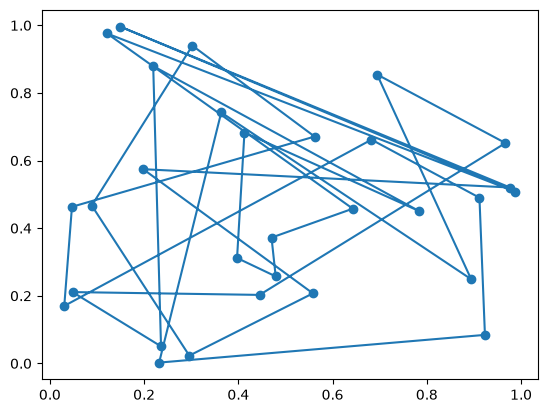

2. Tour sau khi tối ưu bằng Simulated Annealing (swap):
Tour length: 6.24


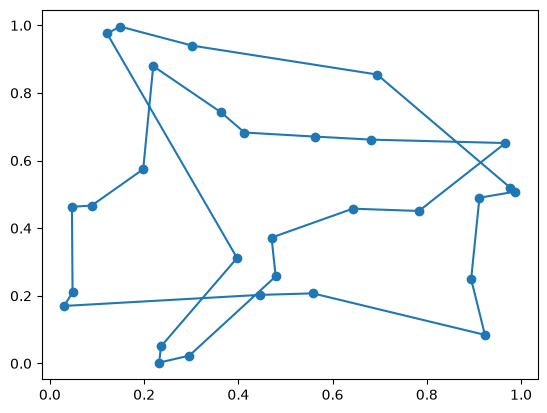

3. Tour sau khi tối ưu bằng Steepest-Ascent (2-opt):
Tour length: 4.99


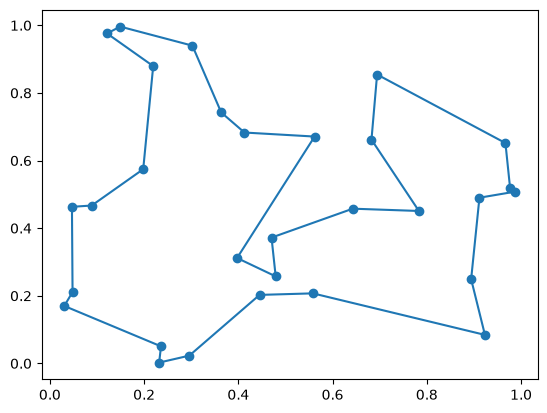

In [26]:
city_sizes = [10, 20, 30, 50]
n_runs_tsp = 10
tsp_results = []

for n_cities in city_sizes:
    np.random.seed(1234 + n_cities)
    random.seed(1234 + n_cities)
    instance = random_tsp(n_cities)
    init_tours = [random_tour(n_cities) for _ in range(n_runs_tsp)]
    init_avg = np.mean([tour_length(instance, t) for t in init_tours])

    methods = [
        ("Steepest-Ascent HC (swap)", lambda t: tsp_steepest_ascend_hc(instance, t, operator="swap", return_stats=True)),
        ("Random Restart HC (10x, swap)", lambda t: tsp_random_restart_hc(instance, restarts=10, operator="swap", return_stats=True)),
        ("Stochastic HC (swap)", lambda t: tsp_stochastic_hc(instance, t, operator="swap", return_stats=True)),
        ("First-Choice HC (swap)", lambda t: tsp_first_choice_hc(instance, t, operator="swap", return_stats=True)),
        ("Simulated Annealing (swap)", lambda t: tsp_simulated_annealing(instance, t, T0=0.5, alpha=0.995, max_iter=4000, operator="swap", return_stats=True)),
        ("Steepest-Ascent HC (2-opt)", lambda t: tsp_steepest_ascend_hc(instance, t, operator="2opt", return_stats=True))
    ]

    for m_name, m_fn in methods:
        lengths = []
        times_ms = []
        steps_arr = []
        for t in init_tours:
            t0 = time.perf_counter()
            _, l_val, st_val, _ = m_fn(t)
            times_ms.append((time.perf_counter() - t0) * 1000.0)
            lengths.append(l_val)
            steps_arr.append(st_val)

        avg_len = np.mean(lengths)
        best_len = np.min(lengths)
        impr = (init_avg - avg_len) / init_avg * 100.0
        tsp_results.append({
            "Cities (n)": n_cities,
            "Algorithm": m_name,
            "Init Tour Avg": round(init_avg, 2),
            "Best Length": round(best_len, 2),
            "Avg Length": round(avg_len, 2),
            "Improvement (%)": f"{impr:.1f}%",
            "Avg Steps": round(np.mean(steps_arr), 1),
            "Avg Time (ms)": round(np.mean(times_ms), 2)
        })

df_tsp = pd.DataFrame(tsp_results)
print(df_tsp.to_markdown(index=False))

# Minh họa trực quan tour trước và sau khi tối ưu trên bài toán 30 thành phố
np.random.seed(2026)
random.seed(2026)
tsp_30 = random_tsp(30)
init_30 = random_tour(30)
best_sa_30 = tsp_simulated_annealing(tsp_30, init_30, T0=0.5, alpha=0.997, max_iter=8000, operator="swap")
best_2opt_30 = tsp_steepest_ascend_hc(tsp_30, init_30, operator="2opt")

print("\n--- Minh họa trên n = 30 thành phố ---")
print("1. Tour khởi tạo ngẫu nhiên:")
show_tsp(tsp_30, init_30)
print("2. Tour sau khi tối ưu bằng Simulated Annealing (swap):")
show_tsp(tsp_30, best_sa_30)
print("3. Tour sau khi tối ưu bằng Steepest-Ascent (2-opt):")
show_tsp(tsp_30, best_2opt_30)

## Bonus: Genetic Algorithm [+1 Point]

[Bonus - Genetic Algorithm trên 30 thành phố] Chiều dài tour tốt nhất: 5.5551
Tour length: 5.56


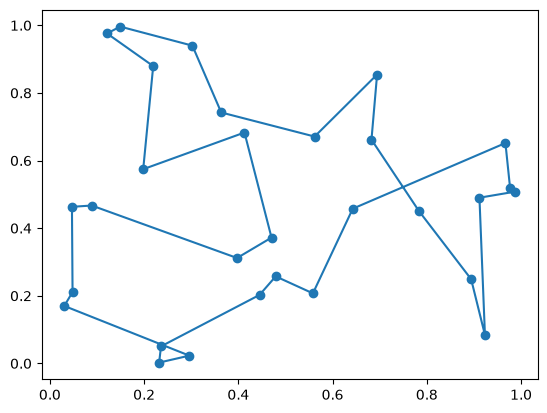

In [27]:
def order_crossover(p1, p2):
    """Toán tử lai ghép thứ tự (Order Crossover - OX) đảm bảo giữ đúng hoán vị các thành phố."""
    n = len(p1)
    a, b = sorted(random.sample(range(n), 2))
    child = [-1] * n
    child[a:b+1] = p1[a:b+1]
    used = set(child[a:b+1])
    pos = (b + 1) % n
    for city in p2[b+1:] + p2[:b+1]:
        if city not in used:
            child[pos] = city
            pos = (pos + 1) % n
    return child

def tsp_genetic_algorithm(tsp, pop_size=80, generations=250, mutation_rate=0.2):
    n = len(tsp["pos"])
    pop = [random_tour(n) for _ in range(pop_size)]

    for _ in range(generations):
        lengths = np.array([tour_length(tsp, ind) for ind in pop])
        fitness = 1.0 / (lengths + 1e-6)
        probs = fitness / fitness.sum()

        elite_idx = np.argsort(lengths)[:pop_size // 10]
        new_pop = [pop[i].copy() for i in elite_idx]

        while len(new_pop) < pop_size:
            idx1, idx2 = np.random.choice(pop_size, size=2, replace=False, p=probs)
            child = order_crossover(pop[idx1], pop[idx2])
            if random.random() < mutation_rate:
                i, j = sorted(random.sample(range(n), 2))
                child[i], child[j] = child[j], child[i]
            new_pop.append(child)
        pop = new_pop

    lengths = [tour_length(tsp, ind) for ind in pop]
    best_idx = int(np.argmin(lengths))
    return pop[best_idx], lengths[best_idx]

random.seed(1234)
np.random.seed(1234)
ga_tour, ga_len = tsp_genetic_algorithm(tsp_30)
print(f"[Bonus - Genetic Algorithm trên 30 thành phố] Chiều dài tour tốt nhất: {ga_len:.4f}")
show_tsp(tsp_30, ga_tour)